# Visualizing env.py Outputs

## Importing the Environment
- Specific to my personal project directory.
- Uses the Python version in my .venv

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("/Users/qxd/Programming/bluffbot")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from bluffbot.env import HeadsUpEnv

print("Python:", sys.executable)
print("Project:", PROJECT_ROOT)

assert Path(sys.prefix).resolve() == (PROJECT_ROOT / ".venv").resolve(), (
    "Select the project's .venv kernel before continuing."
)

Matplotlib is building the font cache; this may take a moment.


Python: /Users/qxd/Programming/bluffbot/.venv/bin/python
Project: /Users/qxd/Programming/bluffbot


## Definitions
- Labels observations
- Decodes cards
- Shows legal actions
- Reads only from the environment

In [2]:
ACTION_NAMES = [
    "Fold",
    "Check/Call",
    "Minimum bet/raise",
    "All-in raise",
]

FEATURE_NAMES = [
    "Own card 1 — encoded",
    "Own card 2 — encoded",
    "Board card 1 — encoded",
    "Board card 2 — encoded",
    "Board card 3 — encoded",
    "Board card 4 — encoded",
    "Board card 5 — encoded",
    "Learner stack — BB",
    "Opponent stack — BB",
    "Learner street contribution — BB",
    "Opponent street contribution — BB",
    "Street — encoded",
    "Pot — BB",
    "Amount to call — BB",
    "Learner is button",
]

CARD_BY_ID = {
    number: str(card)
    for card, number in HeadsUpEnv.CARD_IDS.items()
}

STREET_NAMES = ["Preflop", "Flop", "Turn", "River"]


def decode_cards(values):
    return [
        CARD_BY_ID.get(int(round(float(value) * 52)), "—")
        for value in values
    ]


def show_state(env, observation, info):
    active = bool(env.state.status)

    print("Hand active:", active)
    print(
        "Learner position:",
        "Button / small blind"
        if info["learner_is_button"]
        else "Big blind",
    )

    if active:
        street = int(round(float(observation[11]) * 3))
        print("Street:", STREET_NAMES[street])
    else:
        print("Street: hand finished")

    print("Own cards:", " ".join(decode_cards(observation[:2])))
    print("Board:", " ".join(decode_cards(observation[2:7])))
    print("Learner decisions:", info["learner_decisions"])

    display(pd.DataFrame({
        "Player": ["Learner", "Opponent"],
        "Stack (BB)": observation[7:9],
        "Street contribution (BB)": observation[9:11],
    }))

    print(f"Pot: {observation[12]:.1f} BB")
    print(f"Amount to call: {observation[13]:.1f} BB")

    display(pd.DataFrame({
        "Action ID": range(len(ACTION_NAMES)),
        "Action": ACTION_NAMES,
        "Legal": env.action_masks(),
    }))

    if not active:
        print(f"Final profit: {info['profit_bb']:+.1f} BB")

## Sequence of Events Showcase
### **Preflop**

In [11]:
env = HeadsUpEnv()

observation, info = env.reset(seed=42)

reward = 0.0
terminated = False
truncated = False

show_state(env, observation, info)

Hand active: True
Learner position: Button / small blind
Street: Preflop
Own cards: TREY OF SPADES (3s) JACK OF HEARTS (Jh)
Board: — — — — —
Learner decisions: 0


,Player,Stack (BB),Street contribution (BB)
0,Learner,99.5,0.5
1,Opponent,99.0,1.0


Pot: 1.5 BB
Amount to call: 0.5 BB


,Action ID,Action,Legal
0,0,Fold,True
1,1,Check/Call,True
2,2,Minimum bet/raise,True
3,3,All-in raise,True


In [4]:
display(pd.DataFrame({
    "Index": range(len(FEATURE_NAMES)),
    "Feature": FEATURE_NAMES,
    "Value": observation,
}))

print(
    "Matches declared observation space:",
    env.observation_space.contains(observation),
)

,Index,Feature,Value
0,0,Own card 1 — encoded,0.153846
1,1,Own card 2 — encoded,0.750000
2,2,Board card 1 — encoded,0.000000
3,3,Board card 2 — encoded,0.000000
4,4,Board card 3 — encoded,0.000000
5,5,Board card 4 — encoded,0.000000
6,6,Board card 5 — encoded,0.000000
7,7,Learner stack — BB,99.500000
8,8,Opponent stack — BB,99.000000
9,9,Learner street contribution — BB,0.500000


Matches declared observation space: True


### **Action Step**
Run this action step repeatedely instead of an action step corresponding to flop, turn, river. This is how the simulation loop works in env.py.

In [9]:
action = 1  # 0=fold, 1=check/call, 2=min raise, 3=all-in raise

if terminated:
    print("Hand finished. Run Cell 3 to start again.")

elif not env.action_space.contains(action):
    print("Unknown action ID.")

elif not env.action_masks()[action]:
    print(f"Currently illegal: {ACTION_NAMES[action]}")

else:
    before = observation.copy()

    observation, reward, terminated, truncated, info = env.step(action)

    print("Selected action:", ACTION_NAMES[action])
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)

    display(pd.DataFrame({
        "Feature": FEATURE_NAMES,
        "Before": before,
        "After": observation,
    }))

    show_state(env, observation, info)

Hand finished. Run Cell 3 to start again.


### **Automatic Action Until Hand Finishes**

In [12]:
while not terminated:
    observation, reward, terminated, truncated, info = env.step(1)

    print(
        f"Decision {info['learner_decisions']}: "
        f"reward={reward:+.1f} BB, finished={terminated}"
    )

show_state(env, observation, info)

assert sum(info["final_stacks"]) == 400
assert reward == info["profit_bb"]

print("Settlement checks passed.")

Decision 1: reward=+0.0 BB, finished=False
Decision 2: reward=+0.0 BB, finished=False
Decision 3: reward=+0.0 BB, finished=False
Decision 4: reward=+1.0 BB, finished=True
Hand active: False
Learner position: Button / small blind
Street: hand finished
Own cards: TREY OF SPADES (3s) JACK OF HEARTS (Jh)
Board: SIX OF DIAMONDS (6d) TREY OF DIAMONDS (3d) ACE OF DIAMONDS (Ad) SEVEN OF SPADES (7s) NINE OF DIAMONDS (9d)
Learner decisions: 4


,Player,Stack (BB),Street contribution (BB)
0,Learner,101.0,0.0
1,Opponent,99.0,0.0


Pot: 0.0 BB
Amount to call: 0.0 BB


,Action ID,Action,Legal
0,0,Fold,False
1,1,Check/Call,False
2,2,Minimum bet/raise,False
3,3,All-in raise,False


Final profit: +1.0 BB
Settlement checks passed.


## Immediate Folding Showcase
By setting fold_env.step() to fold_env.step(0)

In [14]:
fold_env = HeadsUpEnv()
fold_env.reset(seed=42)

fold_obs, fold_reward, fold_done, _, fold_info = fold_env.step(0)

assert fold_done
assert fold_reward == -0.5
assert sum(fold_info["final_stacks"]) == 400

print("Expected reward: -0.5 BB")
print("Actual reward:", fold_reward, "BB")

show_state(fold_env, fold_obs, fold_info)

Expected reward: -0.5 BB
Actual reward: -0.5 BB
Hand active: False
Learner position: Button / small blind
Street: hand finished
Own cards: — —
Board: — — — — —
Learner decisions: 1


,Player,Stack (BB),Street contribution (BB)
0,Learner,99.5,0.0
1,Opponent,100.5,0.0


Pot: 0.0 BB
Amount to call: 0.0 BB


,Action ID,Action,Legal
0,0,Fold,False
1,1,Check/Call,False
2,2,Minimum bet/raise,False
3,3,All-in raise,False


Final profit: -0.5 BB


## Random Simulation of 1000 Hands

In [17]:
simulation = HeadsUpEnv()
action_rng = np.random.default_rng(123)

records = []
action_counts = np.zeros(len(ACTION_NAMES), dtype=int)

for hand in range(1_000):
    obs, hand_info = simulation.reset(
        seed=123 if hand == 0 else None
    )

    done = False
    decisions = 0

    while not done:
        assert simulation.observation_space.contains(obs)

        legal_actions = np.flatnonzero(
            simulation.action_masks()
        )
        assert len(legal_actions) > 0

        action = int(action_rng.choice(legal_actions))
        action_counts[action] += 1

        obs, hand_reward, done, was_truncated, hand_info = (
            simulation.step(action)
        )

        decisions += 1

        assert not was_truncated
        assert simulation.observation_space.contains(obs)

        if not done:
            assert hand_reward == 0.0

    assert sum(hand_info["final_stacks"]) == 400
    assert hand_reward == hand_info["profit_bb"]

    records.append({
        "hand": hand + 1,
        "profit_bb": hand_reward,
        "learner_decisions": decisions,
        "position": (
            "Button"
            if hand_info["learner_is_button"]
            else "Big blind"
        ),
    })

results = pd.DataFrame(records)
results["cumulative_profit_bb"] = results["profit_bb"].cumsum()

print(f"Completed {len(results):,} hands.")
print("All simulation checks passed.")

display(results.head(10))

Completed 1,000 hands.
All simulation checks passed.


,hand,profit_bb,learner_decisions,position,cumulative_profit_bb
0,1,-0.5,1,Button,-0.5
1,2,-100.0,1,Big blind,-100.5
2,3,-100.0,3,Button,-200.5
3,4,-2.0,4,Big blind,-202.5
4,5,-0.5,1,Button,-203.0
5,6,-100.0,2,Big blind,-303.0
6,7,-100.0,2,Button,-403.0
7,8,-100.0,3,Big blind,-503.0
8,9,-100.0,1,Button,-603.0
9,10,-100.0,1,Big blind,-703.0


### Statistics on Results

In [18]:
summary = pd.Series({
    "Hands": len(results),
    "Learner decisions": results["learner_decisions"].sum(),
    "Total profit (BB)": results["profit_bb"].sum(),
    "Average profit (BB/hand)": results["profit_bb"].mean(),
    "BB/100": 100 * results["profit_bb"].mean(),
    "Average decisions per hand": results["learner_decisions"].mean(),
})

display(summary.to_frame("Value").round(3))

display(
    results.groupby("position").agg(
        hands=("profit_bb", "size"),
        average_profit_bb=("profit_bb", "mean"),
        average_decisions=("learner_decisions", "mean"),
    ).round(3)
)

,Value
Hands,1000.000
Learner decisions,2212.000
Total profit (BB),-4703.000
Average profit (BB/hand),-4.703
BB/100,-470.300
Average decisions per hand,2.212


,hands,average_profit_bb,average_decisions
position,,,
Big blind,500,-11.058,2.392
Button,500,1.652,2.032


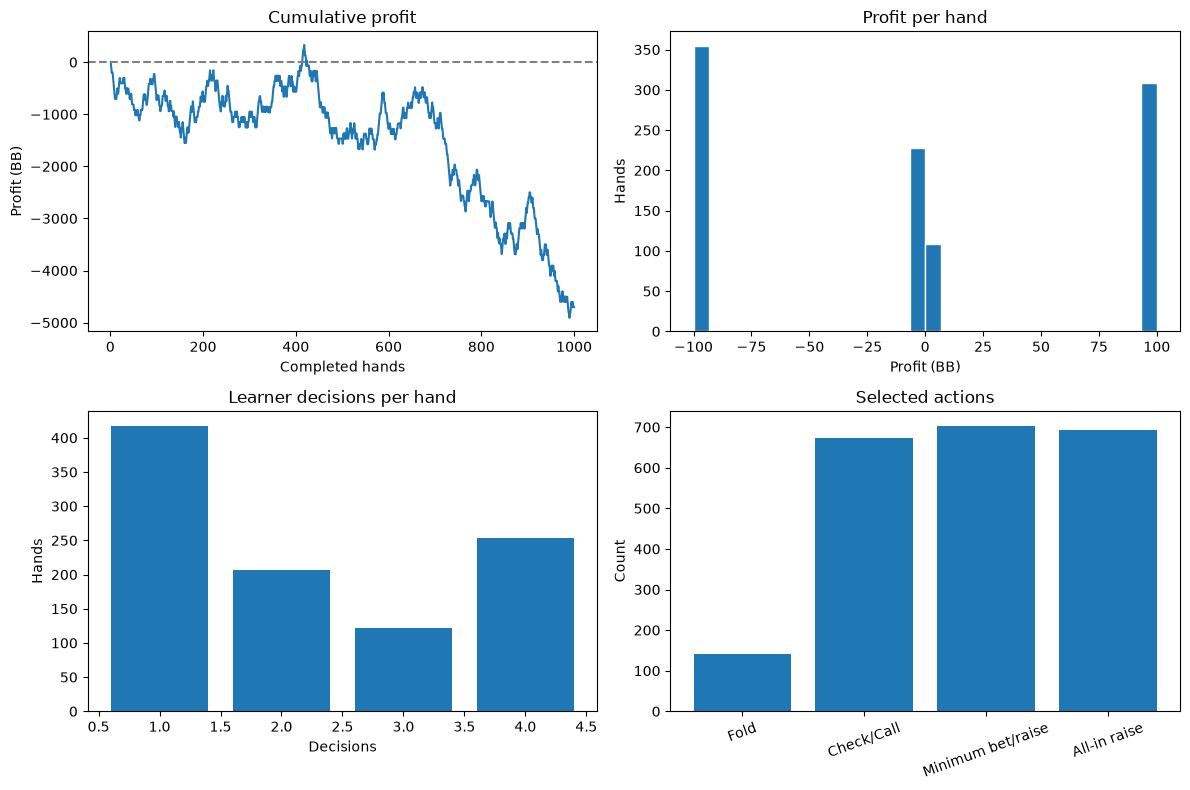

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(
    results["hand"],
    results["cumulative_profit_bb"],
)
axes[0, 0].axhline(0, color="gray", linestyle="--")
axes[0, 0].set(
    title="Cumulative profit",
    xlabel="Completed hands",
    ylabel="Profit (BB)",
)

axes[0, 1].hist(
    results["profit_bb"],
    bins=30,
    edgecolor="white",
)
axes[0, 1].set(
    title="Profit per hand",
    xlabel="Profit (BB)",
    ylabel="Hands",
)

length_counts = (
    results["learner_decisions"]
    .value_counts()
    .sort_index()
)

axes[1, 0].bar(
    length_counts.index,
    length_counts.values,
)
axes[1, 0].set(
    title="Learner decisions per hand",
    xlabel="Decisions",
    ylabel="Hands",
)

axes[1, 1].bar(
    ACTION_NAMES,
    action_counts,
)
axes[1, 1].tick_params(axis="x", labelrotation=20)
axes[1, 1].set(
    title="Selected actions",
    ylabel="Count",
)

plt.tight_layout()
plt.show()